## Analyzes of Fulfillment Optimization

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
simulation_runs = pd.read_excel('./one_day/sim_metrics.xlsx')

In [7]:
del simulation_runs['Unnamed: 0']

In [9]:
simulation_runs.head()

,num_ful_trips,num_miss_trips,ful_rate,distance,co2_emissions,avg_fleet_util,fleet_profit,travel_time,wait_time,costs,n_cars,n_scooters,n_kick_scooters,n_bikes
0,0,15567,0.000000,6.444890e+07,0.000000e+00,inf,0.000000e+00,0.000000,0.000000,0.000000,0,0,0,0
1,6007,9338,0.391463,3.990237e+07,2.891700e+06,0.349444,-1.038412e+07,252781.350800,3.730990,49583.979931,150,150,150,150
2,9669,5497,0.637545,2.449984e+07,4.380653e+06,0.289306,-1.599591e+07,417327.664293,3.654128,77153.939227,300,300,300,300
3,11669,3403,0.774217,1.661528e+07,4.704246e+06,0.240301,-1.834066e+07,522739.093997,3.565222,89366.845134,450,450,450,450
4,12592,2415,0.839075,1.248947e+07,4.589553e+06,0.198229,-1.879569e+07,588375.019650,3.521448,93239.397155,600,600,600,600


## Find optimization convergence for fulfillment Rate

When the fulfillment rate will not get better by more than 1 percent, when increasing all vehicle modes by 150 vehicles each, we can say that the optimization has converged

In [59]:
old_fulfillment_rate = -10.0
conv_threshold = 0.025
optimal_solution = None
old_row = None

for index, row in simulation_runs.iterrows():
    if (row['ful_rate'] - old_fulfillment_rate) < conv_threshold:
        optimal_solution = old_row
        break

    old_fulfillment_rate = row['ful_rate']
    old_row = row

print(optimal_solution)

num_ful_trips      1.355200e+04
num_miss_trips     1.362000e+03
ful_rate           9.086764e-01
distance           8.181657e+06
co2_emissions      4.491275e+06
avg_fleet_util     1.465046e-01
fleet_profit      -1.809505e+07
travel_time        6.912740e+05
wait_time          3.409850e+00
costs              9.657492e+04
n_cars             9.000000e+02
n_scooters         9.000000e+02
n_kick_scooters    9.000000e+02
n_bikes            9.000000e+02
Name: 6, dtype: float64


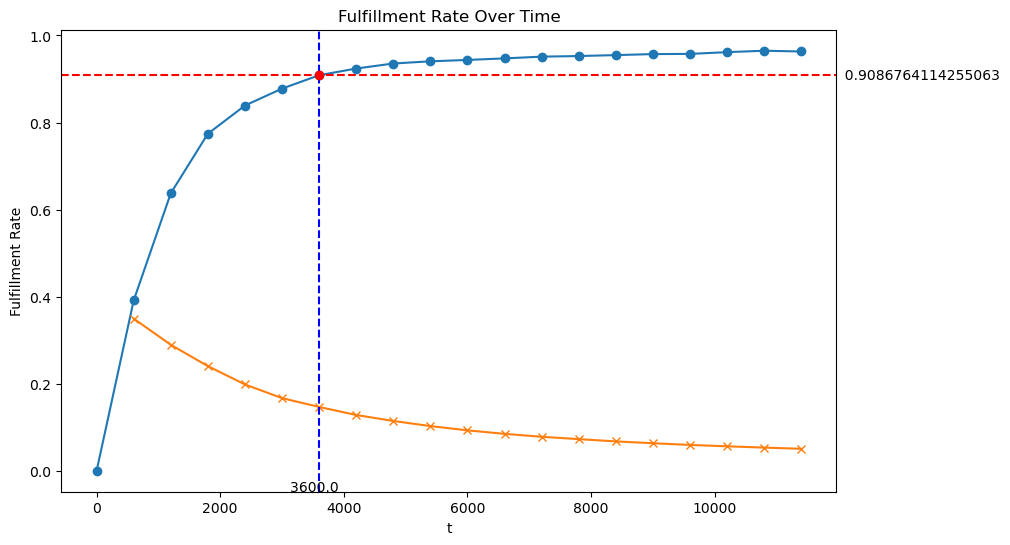

In [60]:
plt.figure(figsize=(10, 6))
x_values = [n*4 for n in simulation_runs['n_cars']]
plt.plot(x_values, simulation_runs['ful_rate'], marker='o')
plt.plot(x_values, simulation_runs['avg_fleet_util'], marker='x', label='Average Fleet Utilization')

plt.scatter(optimal_solution['n_cars']*4, optimal_solution['ful_rate'], color='red', zorder=5, label='Optimal Row')
plt.axhline(y=optimal_solution['ful_rate'], color='red', linestyle='--', label='Optimal Fulfillment Rate')
plt.axvline(x=optimal_solution['n_cars']*4, color='blue', linestyle='--', label='Optimal n_cars')

plt.text(plt.xlim()[1], optimal_solution['ful_rate'], f'  {optimal_solution["ful_rate"]}', verticalalignment='center')
plt.text(optimal_solution['n_cars']*4, plt.ylim()[0], f'{optimal_solution["n_cars"]*4}  ', horizontalalignment='center')

plt.title('Fulfillment Rate Over Time')
plt.xlabel('t')
plt.ylabel('Fulfillment Rate')

plt.show()